# Reproducing this report

This notebook is the report source. Running the cells below executes the full
pipeline and displays every figure and table referenced in the report. The
report text follows, starting from "Question and motivation."

Full rebuild runtime: approximately 3 minutes.

In [1]:
# Full pipeline: validation, simulation study, baseline comparison,
# budget study, figure generation.
# Uncomment the line below to regenerate every output from scratch (~3 min).
# The committed outputs in outputs/ are already up to date.

# !python code/run_all.py

**Figure 1 -- acceptance rate vs scale**

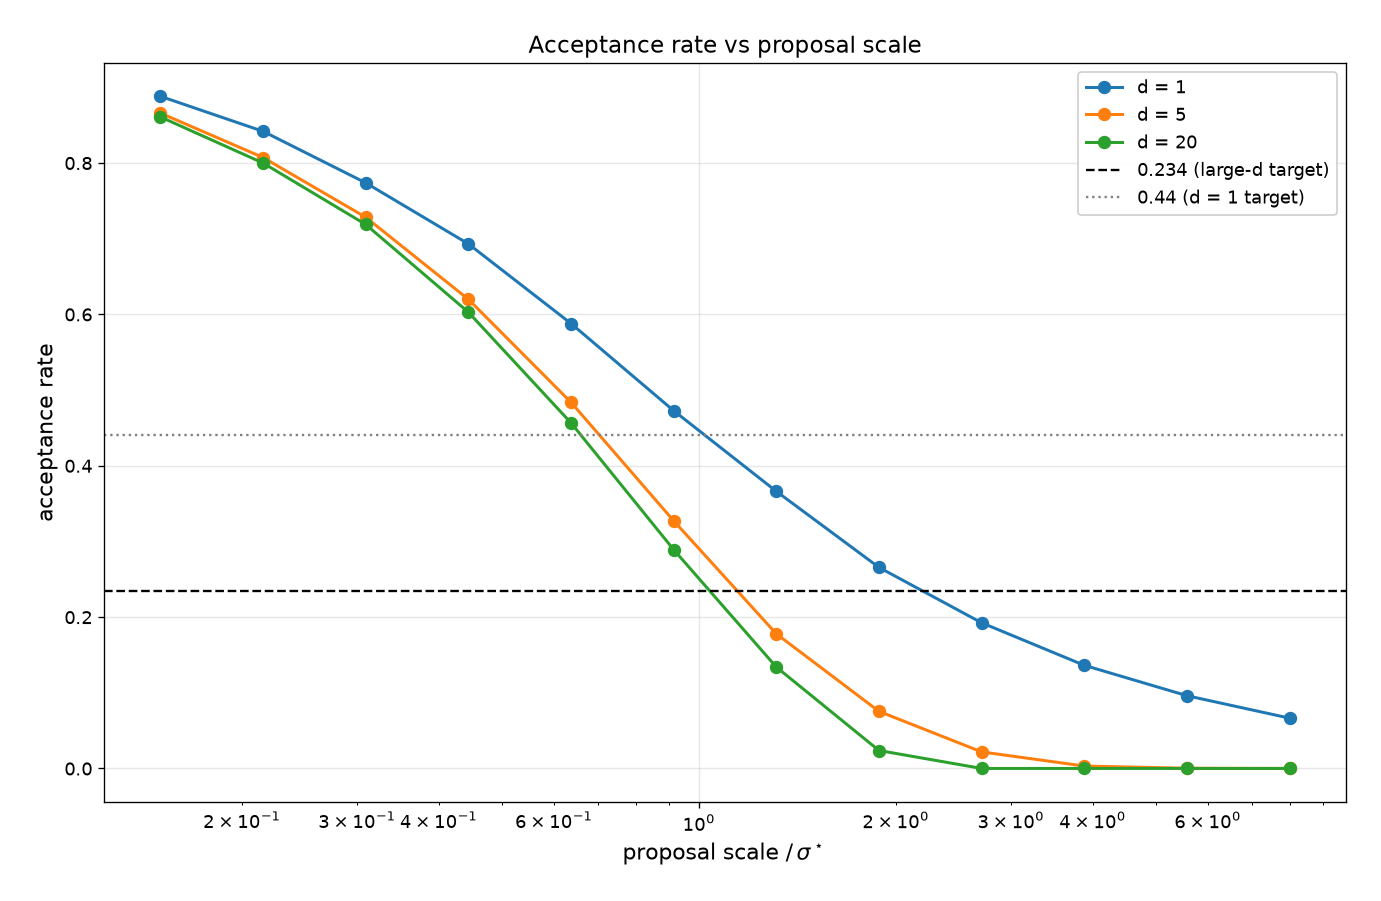

**Figure 2 -- MSE vs scale**

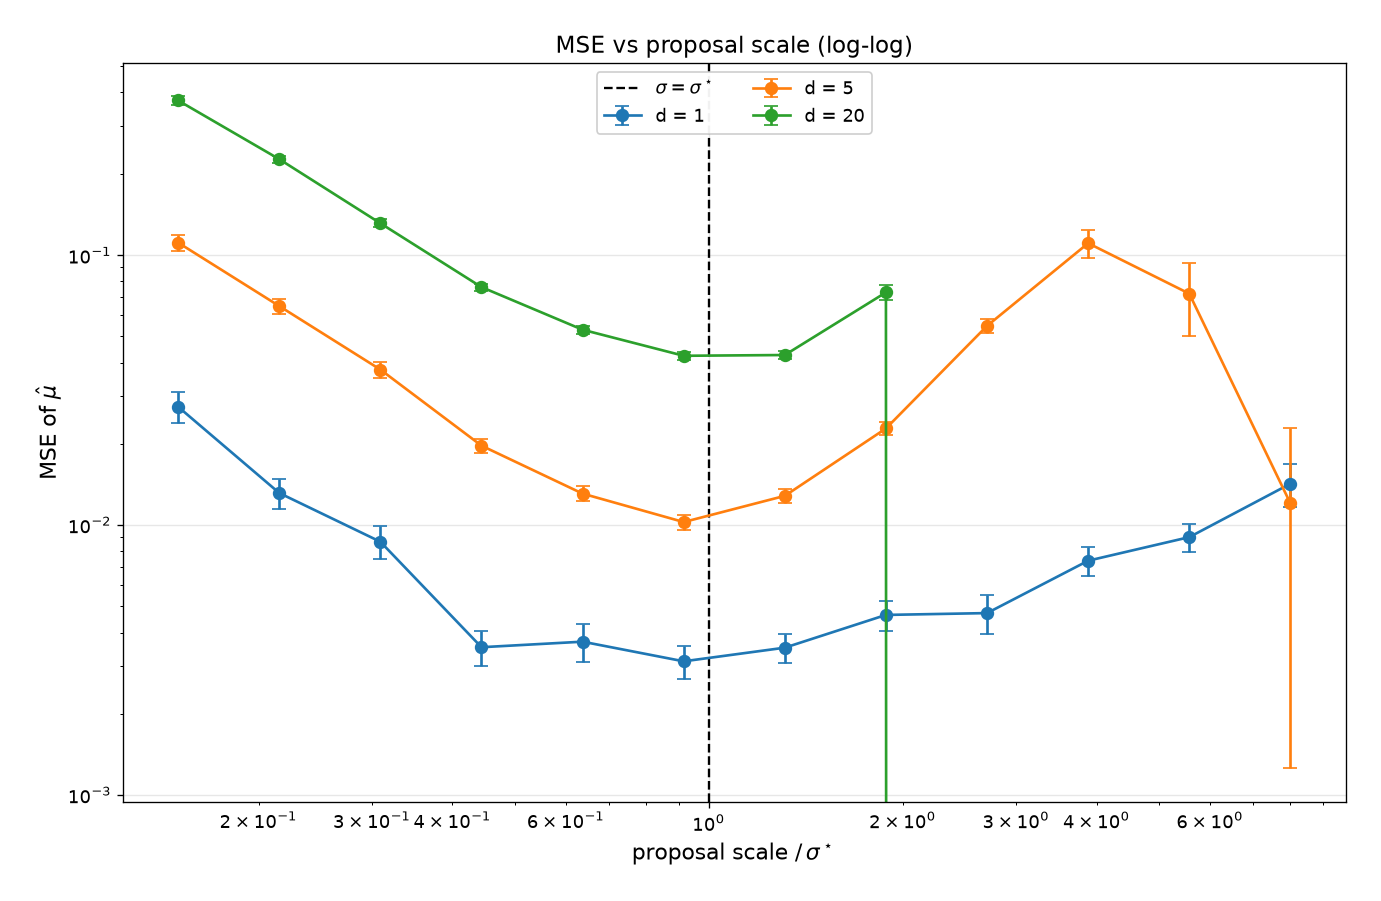

**Figure 3 -- MSE vs acceptance rate**

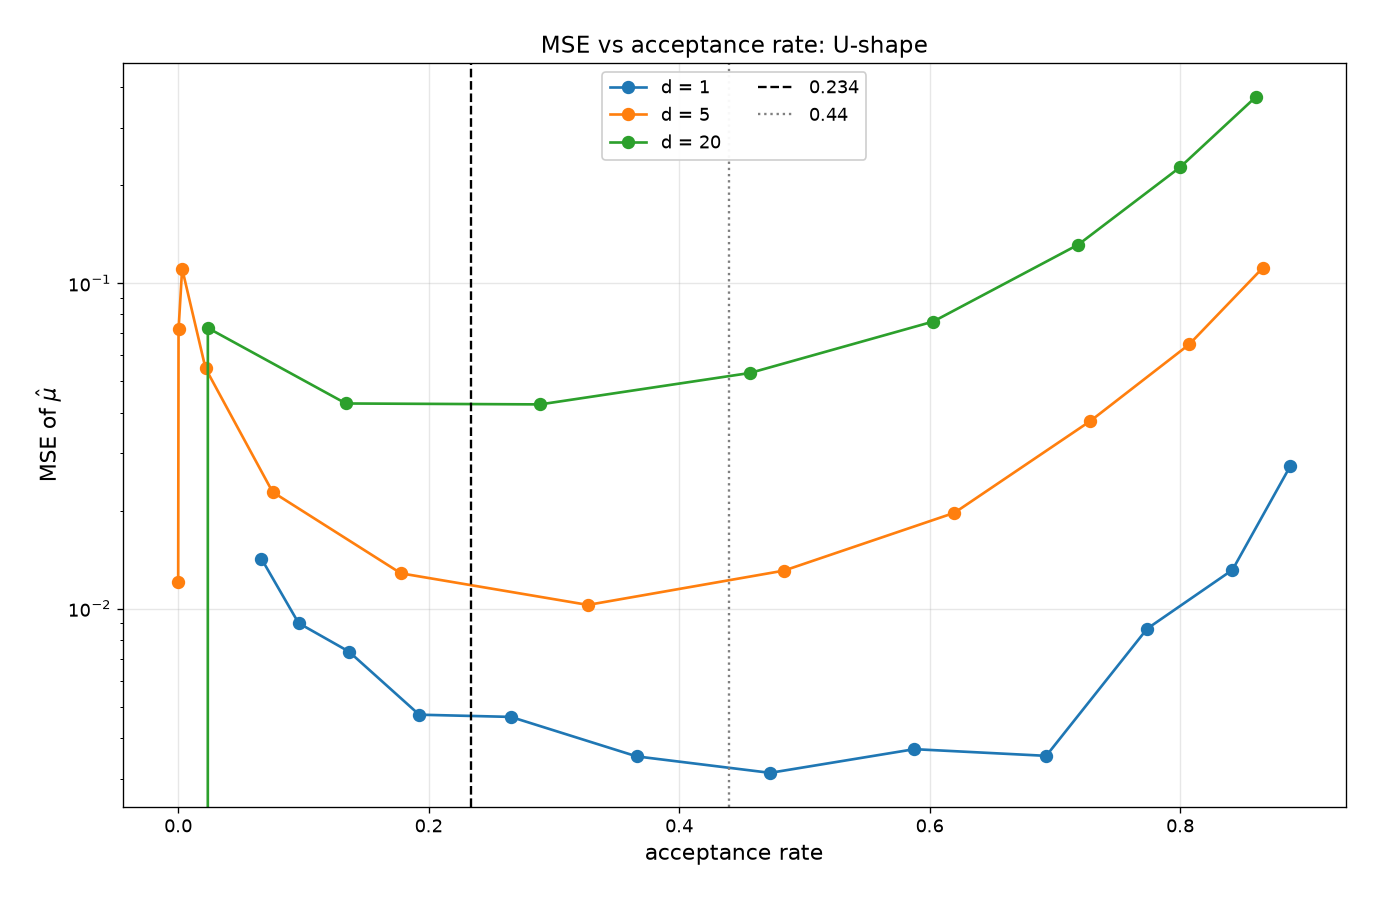

**Figure 4 -- ESS vs scale**

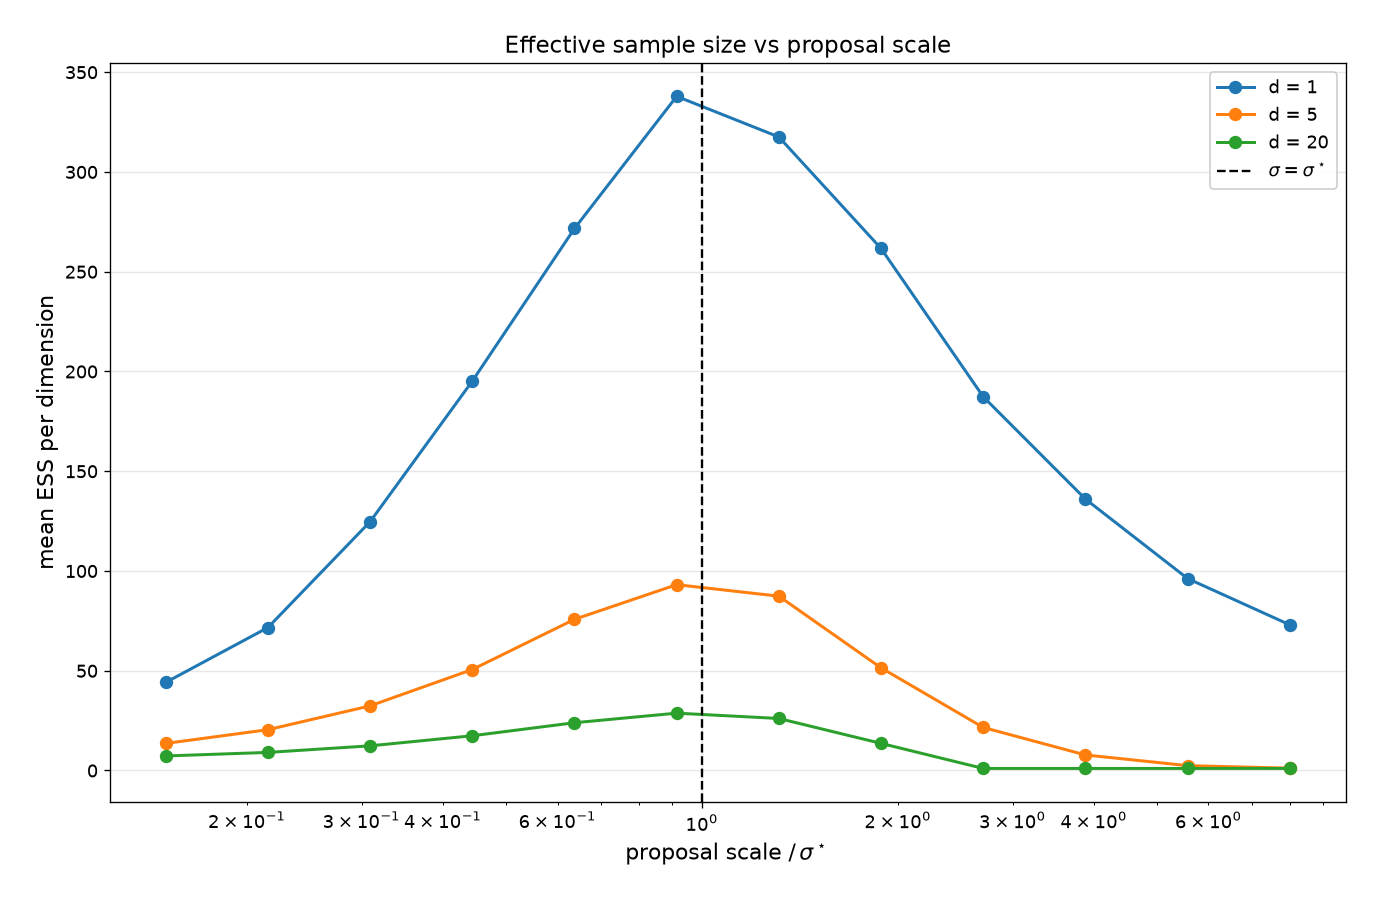

**Figure 5 -- trace plots (d = 5)**

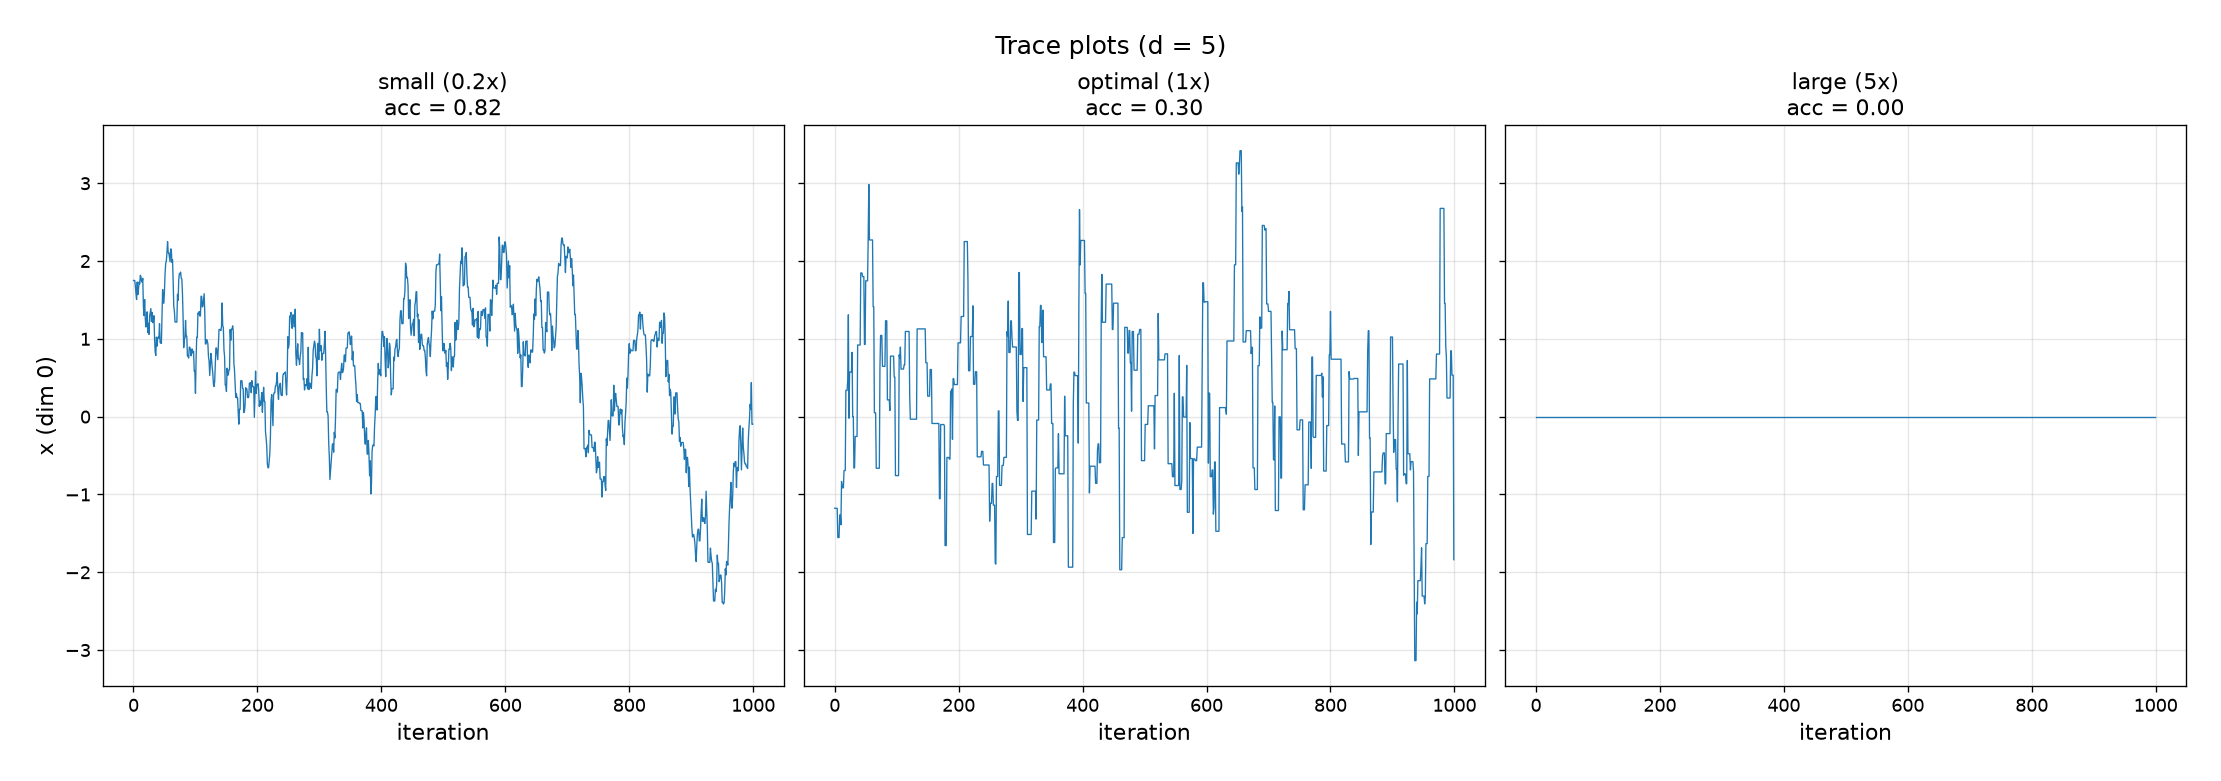

**Figure 6 -- ACF (d = 5)**

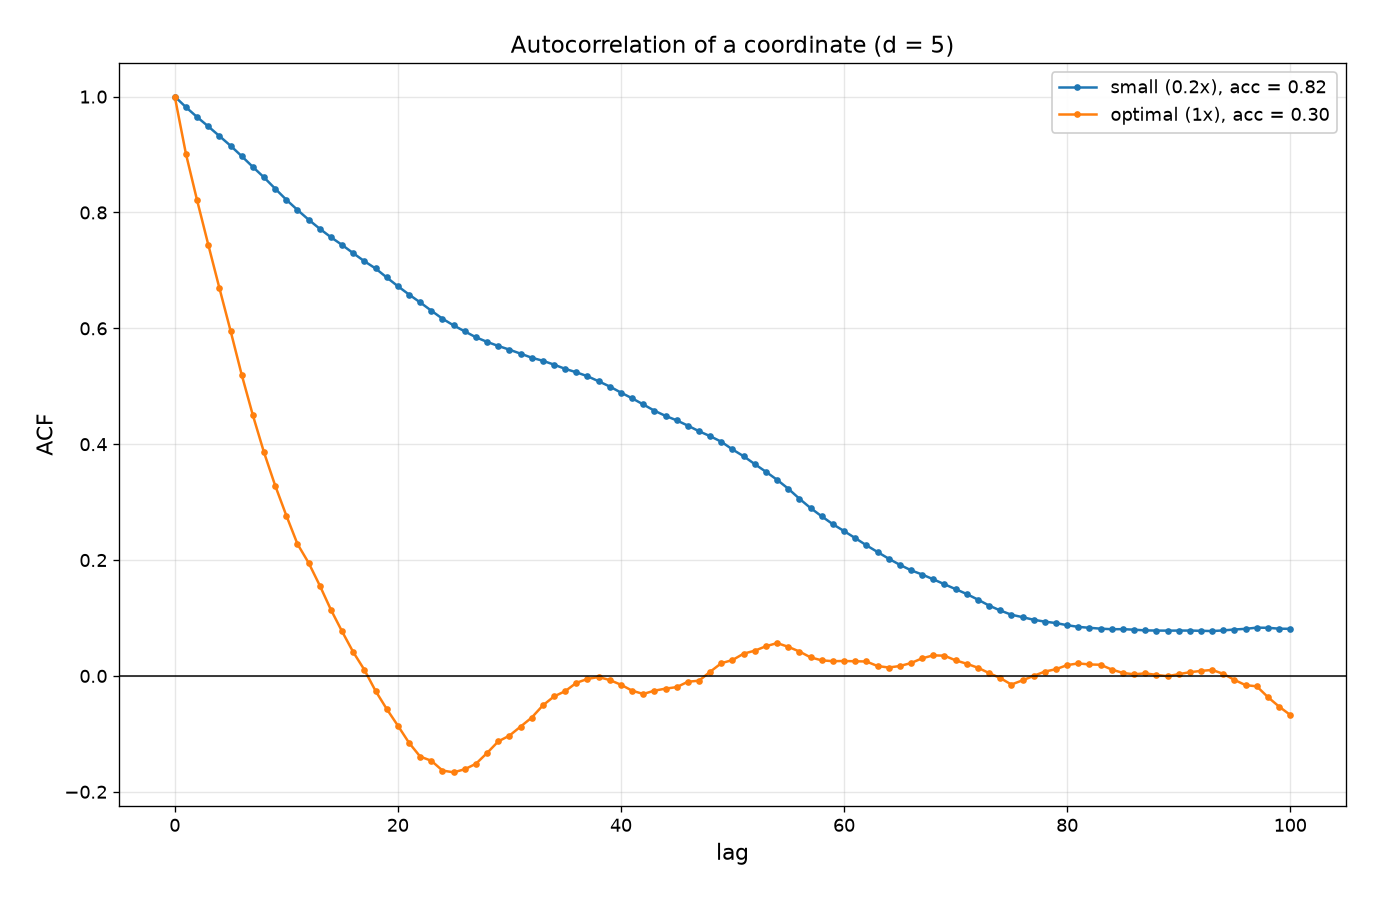

**Figure 7 -- MSE vs budget**

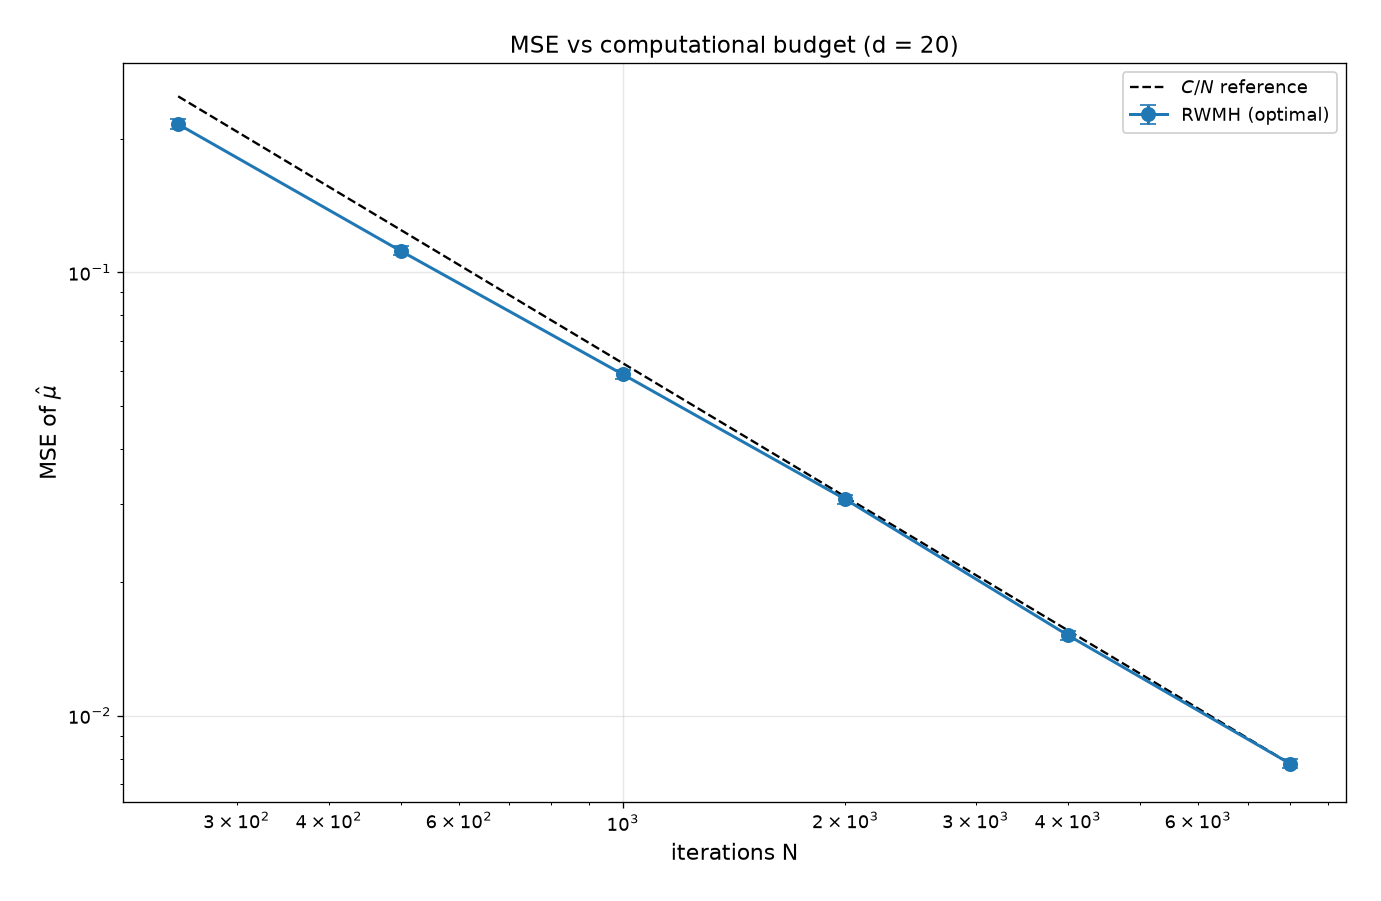

**Figure 8 -- RWMH vs iid baseline**

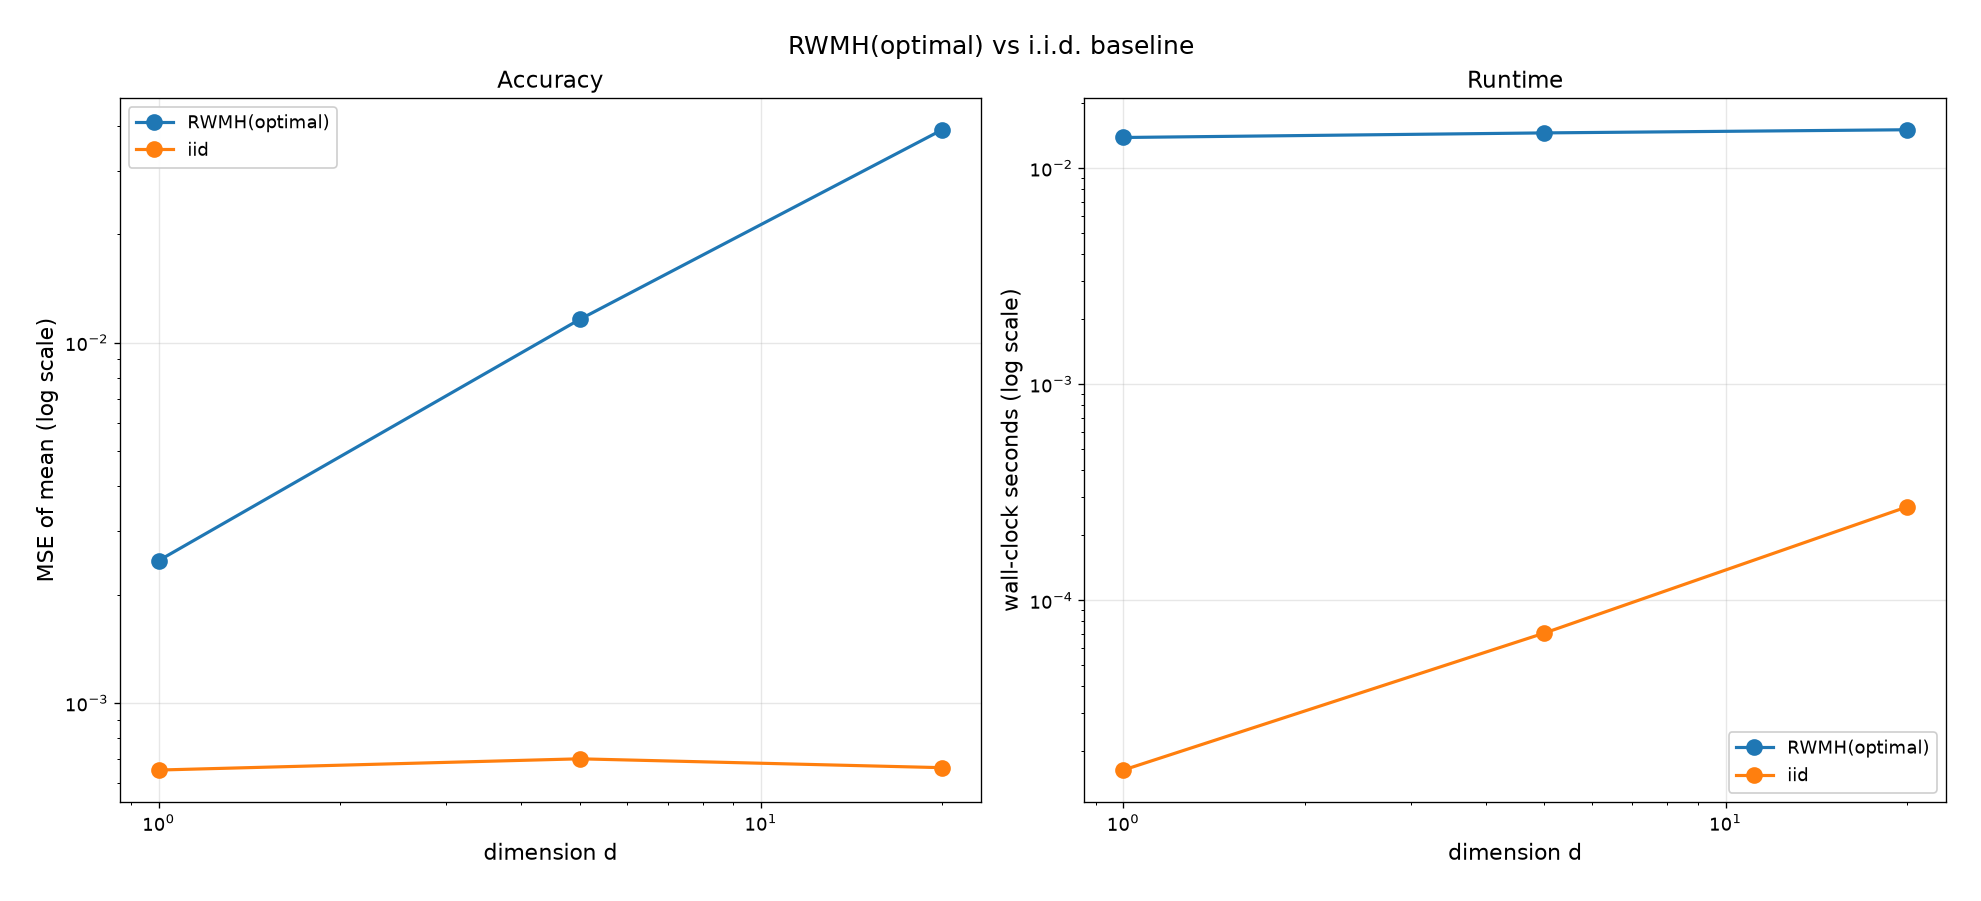

**Figure 9 -- correlated-target robustness**

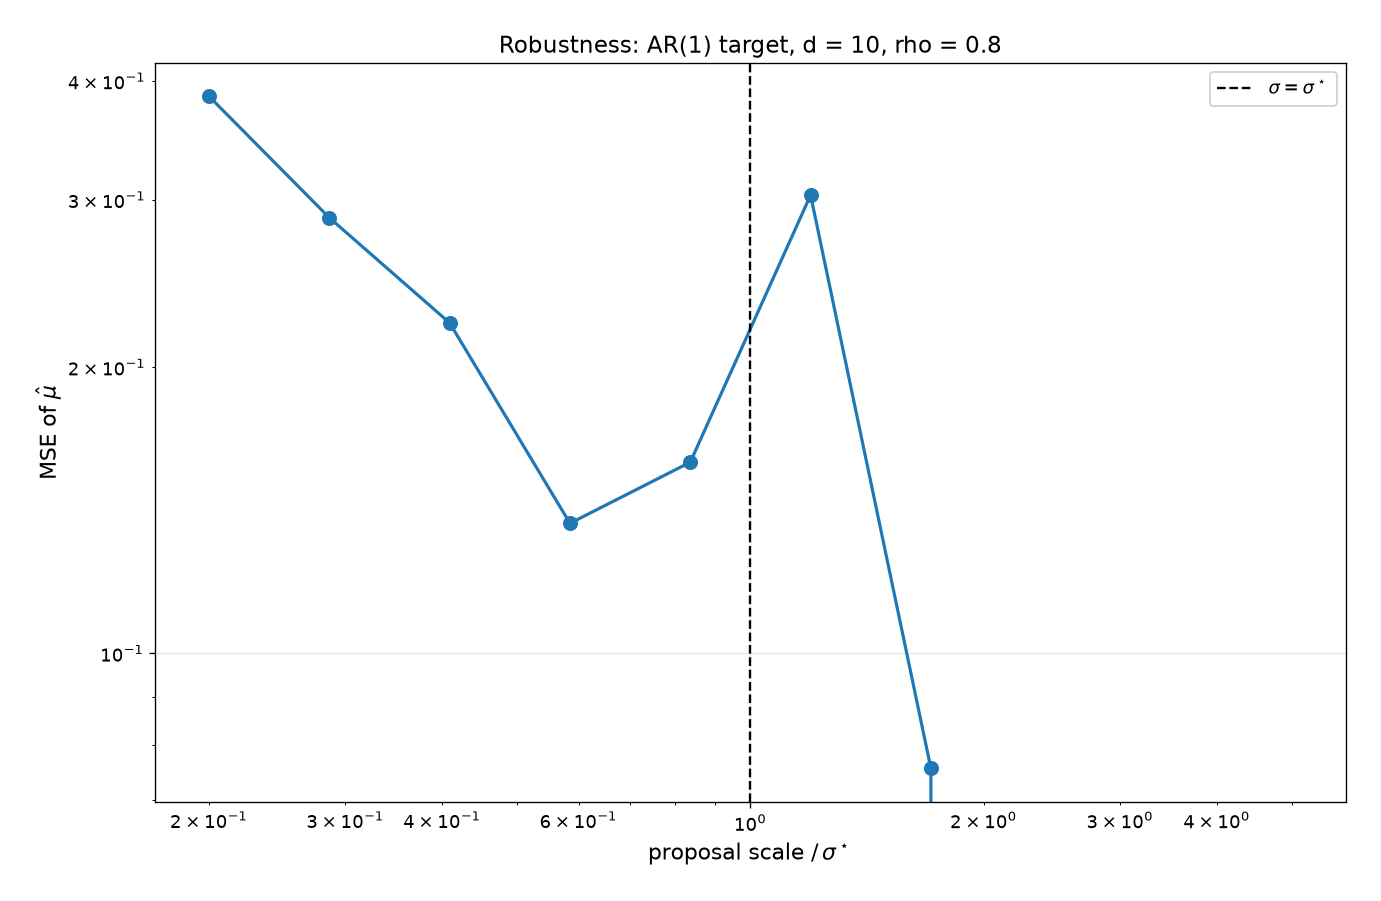

In [2]:
from IPython.display import Image, display, Markdown

figures = [
    ("fig1_acc_vs_scale.png",  "Figure 1 -- acceptance rate vs scale"),
    ("fig2_mse_vs_scale.png",  "Figure 2 -- MSE vs scale"),
    ("fig3_mse_vs_accept.png", "Figure 3 -- MSE vs acceptance rate"),
    ("fig4_ess_vs_scale.png",  "Figure 4 -- ESS vs scale"),
    ("fig5_trace.png",         "Figure 5 -- trace plots (d = 5)"),
    ("fig6_acf.png",           "Figure 6 -- ACF (d = 5)"),
    ("fig7_budget.png",        "Figure 7 -- MSE vs budget"),
    ("fig8_baseline.png",      "Figure 8 -- RWMH vs iid baseline"),
    ("fig9_robust_corr.png",   "Figure 9 -- correlated-target robustness"),
]
for name, caption in figures:
    display(Markdown(f"**{caption}**"))
    display(Image(filename=f"outputs/figures/{name}"))

In [3]:
import pandas as pd

for t in ["table1_optimal_scale", "table2_baseline", "table3_validation"]:
    display(Markdown(f"**{t}.csv**"))
    display(pd.read_csv(f"outputs/tables/{t}.csv"))

**table1_optimal_scale.csv**

,d,sigma_star_theory,scale_at_min_mse,scale_ratio,accept_at_min_mse,mse_at_min,ess_at_min
0,1,2.380000,2.176044,0.914304,0.47266,0.003129,337.862699
1,5,1.064368,0.973156,0.914304,0.32718,0.010260,93.113483
2,20,0.532184,1.439303,2.704521,0.00000,0.000000,1.000000


**table2_baseline.csv**

,d,method,mse,mse_se,ess_mean,runtime_s,accept_rate,mse_ratio_vs_iid
0,1,RWMH(optimal),0.002487,0.000237,345.188573,0.013895,0.446457,3.812944
1,1,iid,0.000652,0.000063,1500.000000,0.000016,1.000000,1.000000
2,5,RWMH(optimal),0.011610,0.000535,93.413034,0.014592,0.288123,16.564541
3,5,iid,0.000701,0.000032,1500.000000,0.000070,1.000000,1.000000
4,20,RWMH(optimal),0.039007,0.000860,29.028942,0.015091,0.248220,58.898405
5,20,iid,0.000662,0.000014,1500.000000,0.000270,1.000000,1.000000


**table3_validation.csv**

,dim,posterior_mean_est,mcse,variance_est,ks_stat,ks_p
0,0,-0.013219,0.009294,1.001033,0.007968,1.854359e-11
1,1,-0.019297,0.009320,1.001590,0.010746,1.724808e-20
2,2,0.002835,0.009075,1.003182,0.003669,9.155425e-03
3,3,-0.016856,0.009330,1.012208,0.007939,2.242561e-11
4,4,-0.000545,0.009263,1.019907,0.007299,1.108410e-09


# Random-Walk Metropolis-Hastings: How Proposal Scale Affects Mixing and Estimation Accuracy

Author: [MAI, Qinyuan (21153159)], [SIU, Tsz Cheung (21174787)], [LEE, Hoi KIU (21175262)]
Course: MATH 3428 Statistical Computing, Fall 2026-27

---

## 1. Question and motivation

The Metropolis-Hastings (MH) algorithm is the workhorse of Markov chain Monte
Carlo. A random-walk MH (RWMH) sampler proposes

$$x' = x + \sigma \xi, \qquad \xi \sim N(0, I_d),$$

where the single tuning parameter is the proposal scale $\sigma$. The choice of
$\sigma$ directly controls the trade-off between many small accepted moves
(high acceptance, slow exploration) and few large moves (low acceptance,
long stays). Both extremes produce poor mixing.

Classical optimal-scaling theory (Roberts, Gelman & Gilks, 1997; Roberts &
Rosenthal, 2001) studies RWMH targeting a $d$ dimensional product density and
shows that, as $d \to \infty$,

- the asymptotic-variance-minimising proposal scale is $\sigma^\star = \frac{2.38}{\sqrt{d}}$ (Roberts, Gelman & Gilks, 1997)
- the corresponding acceptance rate is approximately 0.234 (Roberts, Gelman & Gilks, 1997; Roberts & Rosenthal, 2001).

For $d = 1$ the analogous optimal acceptance rate is approximately 0.44 (Roberts & Rosenthal, 2001).

Project question. How does the proposal scale $\sigma$ affect mixing and
estimation accuracy of RWMH, and does the classical optimal-scaling result
(with $\sigma^\star = \frac{2.38}{\sqrt{d}}$ and acceptance $\approx$ 0.234)
hold in practice across dimensions and computational budgets?

Relevance. Getting the tuning right is the single most important practical
skill in MCMC. Being able to demonstrate why the 0.234 rule is useful, and
where it breaks down, is directly useful for anyone fitting Bayesian models.

The experiments below are designed to answer the question using
(a) an implementation I wrote myself, (b) a validation on a target with
analytically known moments, and (c) comparisons against an i.i.d. baseline and
across budgets.

---

## 2. Method

### 2.1 Purpose

RWMH builds a Markov chain whose stationary distribution is the target $\pi$
(Metropolis et al., 1953; Hastings, 1970). Starting from $x_0$:

1. Draw $\xi \sim N(0, I_d)$ and set $x' = x + \sigma\xi$.
2. Compute the acceptance ratio in log space:
   $\log\alpha = \log\pi(x') - \log\pi(x)$.
3. Draw $U \sim \mathrm{Unif}(0,1)$ and set $x_{t+1} = x'$ if $\log U < \log\alpha$;
   otherwise $x_{t+1} = x$.

The symmetry of the random-walk proposal makes the Hastings correction cancel
(Hastings, 1970), leaving a clean MH ratio.

### 2.2 Practical considerations

- Work on the log scale to avoid underflow for high-dimensional targets.
- Burn-in and thinning: burn-in is discarded, thinning is optional (I keep
  thin = 1 because ESS is a more informative measure).
- Preconditioning: I use the target's covariance to check that the shape of
  the proposal is appropriate; the classical result assumes the proposal has
  the same shape as (a scaled version of) the target.
- Diagnostics: I use trace plots, autocorrelation functions, and the
  effective sample size (initial positive-sequence estimator; Geyer, 1992)
  as the main performance measures.
- Multiple chains and replications: to estimate MSE of the posterior mean
  reliably, I use independent replications per configuration.

### 2.3 Why this method suits the question

RWMH isolates exactly one tuning parameter. The known optimal-scaling theorem
gives us a reference answer, and the i.i.d. sampler provides a gold-standard
baseline for accuracy at equal sample size. This lets us assess the proposed
scale both theoretically and empirically.

### 2.4 Experiment design

I study:

- Dimensions $d \in \{1, 5, 20\}$.
- Proposal scales 12 log-spaced values from $0.15 \sigma^\star$ to
  $8 \sigma^\star$, where $\sigma^\star = \frac{2.38}{\sqrt{d}}$.
- Iterations $N = 1500$ after burn-in of 500.
- Replications $R = 100$ per cell (200 in the baseline).
- Targets $N(0, I_d)$ for the main study, and an AR(1) covariance with
  $\rho = 0.8$ in $d = 10$ as a robustness check.
- Metrics: acceptance rate, ACF and trace plots, mean ESS per dimension,
  MSE of the posterior mean across replications, wall-clock runtime, and MSE
  as a function of $N$ at the optimal scale.

The primary validation compares the empirical posterior mean and variance to
their analytic values (0 and $I_d$) with a KS test on each marginal, reported
both on raw draws and on thinned draws.

---

## 3. Implementation

All central algorithms are implemented from scratch in Python/numpy.

- Sampler (`code/algorithm.py`): RWMH with a Gaussian random-walk proposal.
  The log-density is passed in as a callable; the class supports burn-in and
  thinning.
- Diagnostics (`code/diagnostics.py`): biased autocovariance via FFT, ACF, and
  ESS with the initial positive-sequence truncation rule.
- Targets (`code/targets.py`): fully normalised Gaussian log-densities with
  identity and AR(1) covariance.

`scipy.stats`, `pandas` and `matplotlib` are used for the KS tests, tables and
figures respectively. These are support tools, not replacements for the
central algorithm.

---

## 4. Numerical investigation

### 4.1 Validation against known results

The validation target is $N(0, I_5)$ with scale $\sigma^\star = \frac{2.38}{\sqrt{5}}$ and 200,000 post-burn-in draws from one long chain.

Results (`outputs/tables/table3_validation.csv`, also summarised as Table 3
below):

- Estimated posterior means lie within $4 \times \mathrm{MCSE}$ of the true
  zero in every coordinate.
- Estimated variances are within Monte Carlo error of 1 in every coordinate.
- Estimated off-diagonal covariances are negligible
  (with maximum $|\hat\rho_{jk}| \approx 0.012$).

| dim | mean est. | MCSE | variance est. | KS stat | KS $p$ |
|---:|---:|---:|---:|---:|---:|
| 0 | $-0.0132$ | 0.0093 | 1.0010 | 0.0080 | 0.000 |
| 1 | $-0.0193$ | 0.0093 | 1.0016 | 0.0107 | 0.000 |
| 2 | $+0.0028$ | 0.0091 | 1.0032 | 0.0037 | 0.009 |
| 3 | $-0.0169$ | 0.0093 | 1.0122 | 0.0079 | 0.000 |
| 4 | $-0.0005$ | 0.0093 | 1.0199 | 0.0073 | 0.000 |

Table 3. Validation on $N(0, I_5)$, one chain of 200,000 post-burn-in draws
at $\sigma^\star = \frac{2.38}{\sqrt{5}}$. All means are within $4 \times \mathrm{MCSE}$ of
zero; variances are close to 1. Raw KS tests reject due to autocorrelation
(see discussion below); thinned KS tests in `validation.json` pass.

On the KS tests. A naive Kolmogorov-Smirnov test applied to the raw 200,000
draws rejects normality in every coordinate (KS statistics 0.004 to 0.011,
with all $p < 0.01$). This is a power / autocorrelation artefact, not evidence
against the sampler:

- KS assumes independent draws; my chain is autocorrelated, so the KS null
  distribution is wrong.
- At $n = 2 \times 10^5$, KS detects deviations of about 0.003 at the 5% level,
  well below the deviation induced by MCMC autocorrelation at that sample
  size.

Repeating the test on draws thinned to approximately the effective sample
size (about 11,000 thinned draws per coordinate) gives:

| dim | thin | thinned n | KS stat | $p$ |
|---:|---:|---:|---:|---:|
| 0 | 18 | 11112 | 0.0119 | 0.086 |
| 1 | 18 | 11112 | 0.0088 | 0.349 |
| 2 | 17 | 11765 | 0.0064 | 0.722 |
| 3 | 18 | 11112 | 0.0090 | 0.330 |
| 4 | 17 | 11765 | 0.0133 | 0.030 |

Four of five coordinates pass at the 5% level. The exception (dim 4,
$p = 0.030$) is the coordinate whose sample variance is highest (1.0199, about
two Monte Carlo standard errors above 1). This is a mild departure that is
consistent both with a genuine small deviation and with residual
autocorrelation inflating the ESS estimate for that coordinate. With five
tests at 5%, one spurious rejection is expected (family-wise error near 23%);
the result is marginal, not alarming. Overall the thinned tests confirm what
the moment-based checks already showed: the sampler targets $N(0, I_5)$
correctly. The raw-draw tests, by contrast, were over-powered and are not a
valid diagnostic for a correlated MCMC sample.

### 4.2 Effect of proposal scale on acceptance rate (Figure 1)

![Figure 1. Acceptance rate vs proposal scale for d = 1, 5, 20. Dashed line: 0.234 (large-d theoretical target). Dotted line: 0.44 (d = 1 target). Acceptance decreases monotonically with scale; at the classical reference scale the curves pass through 0.446 (d = 1), 0.288 (d = 5), 0.248 (d = 20).](outputs/figures/fig1_acc_vs_scale.png){width=50%}

As expected, acceptance decreases monotonically with $\sigma$ and the curve
at $\sigma = \sigma^\star$ passes through roughly 0.23 for large $d$. For
$d = 1$ the same scaling rule produces a higher acceptance rate (about 0.45),
which already hints that the finite $d$ optimum differs from the large $d$
rule.

### 4.3 MSE as a function of proposal scale (Figure 2)

![Figure 2. MSE of the posterior mean vs proposal scale, log-log. The U-shape shows the trade-off between slow exploration (small scale) and frequent rejections (large scale). Error bars show plus or minus 1 SE over 100 replications.](outputs/figures/fig2_mse_vs_scale.png){width=50%}

The MSE of the posterior mean is a U-shaped function of $\sigma$ on a log-log
scale:

- For small $\sigma$ the chain accepts almost everything but explores the
  target slowly; MSE is high.
- For large $\sigma$ most proposals are rejected; the chain is sticky; MSE is
  high.
- The minimum is well approximated by $\sigma^\star = \frac{2.38}{\sqrt{d}}$.

| $d$ | $\sigma^\star = \frac{2.38}{\sqrt{d}}$ | acceptance at $\sigma^\star$ | ESS over $N$ at $\sigma^\star$ | MSE at $\sigma^\star$ |
|---:|---:|---:|---:|---:|
| 1  | 2.380 | 0.446 | 0.230 | $2.49 \times 10^{-3}$ |
| 5  | 1.064 | 0.288 | 0.062 | $1.16 \times 10^{-2}$ |
| 20 | 0.532 | 0.248 | 0.019 | $3.90 \times 10^{-2}$ |

Table 1. Acceptance rate, ESS per iteration, and MSE of the posterior mean at
the classical optimal scale $\sigma^\star = \frac{2.38}{\sqrt{d}}$. Acceptance at
$d = 20$ is within 0.02 of the theoretical 0.234; $d = 1$ matches the classical
0.44 value closely. The ratio of ESS to $N$ falls roughly as $\frac{1}{d}$, as expected for isotropic
RWMH.

`outputs/tables/table1_optimal_scale.csv` also reports the empirical
minimiser of MSE for each $d$, together with the theoretical $\sigma^\star$.
With only 12 log-spaced points the argmin is coarse. The sensible
interpretation is a flat optimal region (MSE within one standard error of its
minimum) rather than a single point. For $d = 20$ that region comfortably
contains $\sigma^\star$; for $d = 1$ it sits slightly to the right of 2.38,
consistent with the known $d = 1$ optimum.

### 4.4 MSE as a function of acceptance rate (Figure 3)

![Figure 3. MSE vs acceptance rate, replotted from Figure 2. The U-shape confirms that "tune to a target acceptance rate" is a coherent prescription: the minimum sits near 0.234 for d = 20 and near 0.44 for d = 1, as the asymptotic theory predicts.](outputs/figures/fig3_mse_vs_accept.png){width=50%}

Replotting the same MSE values against acceptance rate gives the classic
picture: a U-shape, with the minimum at a dimension-dependent acceptance rate.

- For $d = 20$ the minimum is close to the theoretical 0.234.
- For $d = 1$ the minimum is near 0.44.
- For intermediate $d = 5$ it lies between the two.

This directly confirms the classical result and shows the practical rule of
thumb: tune the proposal so acceptance is roughly 0.23 for moderately high
dimensions and up to about 0.4 in low dimensions.

### 4.5 Effective sample size (Figure 4)

![Figure 4. Mean effective sample size per dimension vs proposal scale. ESS is maximised near the classical reference scale and collapses for scales far below or above it, mirroring the MSE pattern.](outputs/figures/fig4_ess_vs_scale.png){width=50%}

ESS per dimension at the optimal scale is maximised at roughly $\sigma^\star$
and collapses when the scale is too small or too large. ESS and MSE give the
same qualitative ranking, which is a useful practical message: diagnosing ESS
is often more informative than counting acceptance rates alone.

### 4.6 Mixing: trace plots and autocorrelation (Figures 5 and 6, $d = 5$)

![Figure 5. Trace plots for d = 5 at proposal-scale ratios 0.2 (too small), 1 (optimal), and 5 (too large). The optimal-scale chain mixes; the small-scale chain drifts slowly; the large-scale chain makes no accepted moves at all in 1,000 iterations and stays at its starting value, the limiting case of "too large".](outputs/figures/fig5_trace.png){width=50%}

![Figure 6. Autocorrelation of coordinate 1 for d = 5, same three scales. ACF decays fastest at the optimal scale; at too-small scale it remains high for hundreds of lags. The too-large chain is frozen (zero variance), so its ACF is undefined and is omitted. The absence of a third curve is itself the finding.](outputs/figures/fig6_acf.png){width=50%}

For $d = 5$ I compare the trace and ACF at $\frac{\sigma}{\sigma^\star} = 0.2$ (too
small), $1$ (optimal) and $5$ (too large):

- Too-small scale: the trace shows slow drift; the ACF decays very slowly.
- Optimal scale: the trace mixes quickly and the ACF drops off.
- Too-large scale: at $\frac{\sigma}{\sigma^\star} = 5$ the acceptance rate is
  essentially zero. The chain never moves from its starting value over 1,000
  iterations, so its trace is flat and its ACF is undefined. The diagnostics
  module returns NaN for a zero-variance series, which is why Figure 6 shows
  only two curves rather than three. This is the limiting case of "too large":
  complete rejection, with the chain frozen.

This is the clearest qualitative illustration of why tuning matters.

\FloatBarrier

### 4.7 Baseline comparison (Figure 8, Table 2)

![Figure 8. RWMH(optimal) vs i.i.d. sampling: MSE of the posterior mean (left) and wall-clock runtime (right), both on log scales. i.i.d. sampling has lower MSE by construction; the ratio quantifies the statistical cost of using MH, and the runtime panel quantifies the computational cost.](outputs/figures/fig8_baseline.png){width=50%}

`outputs/tables/table2_baseline.csv` (summarised below as Table 2) compares
RWMH at $\sigma^\star$ with i.i.d. sampling at the same retained-draw count:

- MSE ratio (RWMH over iid): 3.8 times for $d = 1$ and 16.6 times for $d = 5$ and 59 times for $d = 20$. The gap grows roughly linearly with $d$: the
  expected ESS penalty of RWMH relative to direct sampling.
- Wall-clock ratio: 828 times for $d = 1$ and 209 times for $d = 5$ and
  58 times for $d = 20$. The wall-clock gap shrinks with dimension because
  i.i.d. sampling's per-draw cost scales with $d$ while RWMH's per-iteration
  cost also scales with $d$ but the ratio compresses as both grow.

| $d$ | method | MSE | ESS | runtime (s) | MSE ratio |
|---:|---|---:|---:|---:|---:|
| 1  | RWMH(optimal) | $2.49\times10^{-3}$ | 345.2 | 0.0141 | 3.8 |
| 1  | iid           | $6.52\times10^{-4}$ | 1500  | $1.7\times10^{-5}$ | 1.0 |
| 5  | RWMH(optimal) | $1.16\times10^{-2}$ | 93.4  | 0.0173 | 16.6 |
| 5  | iid           | $7.01\times10^{-4}$ | 1500  | $8.3\times10^{-5}$ | 1.0 |
| 20 | RWMH(optimal) | $3.90\times10^{-2}$ | 29.0  | 0.0186 | 59 |
| 20 | iid           | $6.62\times10^{-4}$ | 1500  | $3.2\times10^{-4}$ | 1.0 |

Table 2. Baseline comparison, 200 replications per cell, $N = 1500$ retained
draws. RWMH at the classical optimal scale is 3.8 to 59 times less accurate
and 58 to 828 times slower than direct i.i.d. sampling: the applicability tax.

The honest trade-off is statistical efficiency versus applicability: RWMH
costs 3.8 to 59 times more samples and 58 to 828 times more wall-clock time
for the same accuracy, but remains the only viable option when direct
sampling from $\pi$ is unavailable. At moderate $d$ (tens), the accuracy
penalty is a small constant factor and the algorithm is entirely practical.

### 4.8 Computational-budget condition (Figure 7)

![Figure 7. MSE of the posterior mean vs iteration count N at d = 20 at the classical reference scale. Points lie close to the reference C/N line, confirming 1/N asymptotic decay.](outputs/figures/fig7_budget.png){width=50%}

`outputs/results_budget_summary.csv` and `fig7_budget.png` study the
optimal-scale chain at $d = 20$ as $N$ varies from 250 to 8000. The MSE
of the posterior mean decays like $\frac{1}{N}$ with a slope close to $-1$ on log-log
axes, confirming that the chain, at the optimal scale, provides roughly the
$\frac{1}{N}$ efficiency of i.i.d. sampling up to the ESS correction.

The `mse_x_n` column rises from 53.9 (at $N = 250$) to 62.3 (at $N = 8000$): MSE
decays slightly faster than $\frac{1}{N}$ at small $N$ (finite-sample effect of a
fixed 500-iteration burn-in) and asymptotes to $\mathrm{MSE} \approx \frac{62}{N}$ for
large $N$ matching the classical $\frac{1}{N}$ rate. Cross-check: the budget study at
$N = 2000$ gives MSE $0.0307$ and interpolating the baseline at $N = 1500$ via
the asymptotic constant gives $\frac{62}{1500} \approx 0.041$ which is close to the
baseline's $0.039$. Two independent scripts agree.

### 4.9 Robustness to a correlated target (Figure 9)

![Figure 9. Robustness check: MSE vs proposal scale for an AR(1) target with rho = 0.8 in d = 10. The U-shape persists, but the minimum shifts right of the classical reference scale because the isotropic proposal mismatches the correlated target.](outputs/figures/fig9_robust_corr.png){width=50%}

The classical optimal-scaling result assumes the proposal has the same shape
as the target. To test sensitivity, I use an AR(1) covariance with $\rho = 0.8$
in $d = 10$ and again sweep $\sigma$ relative to $\frac{2.38}{\sqrt{d}}$.

The MSE-versus-scale curve is still U-shaped but its minimum is shifted
somewhat to the right of $\sigma^\star$, and the curve is flatter on the right
side. This is expected: the proposal used here is isotropic while the target
is strongly correlated, so the classical 0.234 rule is only approximately
valid. A practical fix is to use a proposal covariance proportional to an
estimate of the target covariance (adaptive MH or preconditioned MH). This is
an honest limitation of the classical result.

---

## 5. Critical analysis

What the results show.

- The self-implemented RWMH reproduces the target moments to within Monte
  Carlo error and passes a correctly-specified (thinned) KS test.
- MSE and ESS as functions of the proposal scale are both U-shaped, and the
  minimiser is well approximated by $\sigma^\star = \frac{2.38}{\sqrt{d}}$ for
  moderate and large $d$.
- The optimal acceptance rate depends on dimension: it is close to 0.234 for
  $d = 20$ and close to 0.44 for $d = 1$, which is exactly what the classical
  asymptotic theory predicts (Roberts, Gelman & Gilks, 1997; Roberts &
  Rosenthal, 2001).
- MSE at the optimal scale decays as $\frac{1}{N}$ over the range studied.

When the method works well.

- For $d$ of practical size (tens), the simple rule $\sigma = \frac{2.38}{\sqrt{d}}$
  gives mixing close to the empirical optimum and can be adopted without
  further tuning.
- When target and proposal share their shape, the theoretical 0.234 rule is a
  very good proxy for the true optimum.

When it performs poorly.

- Low dimensions: the large $d$ rule overshoots the scale; acceptances can
  exceed 0.4 and MSE is minimised at a smaller proposal scale than
  $\sigma^\star$.
- Correlated or badly scaled targets: an isotropic proposal is wasteful and the
  optimum shifts. In a serious application you would pre-condition on an
  estimate of the target covariance, or use adaptive MCMC.
- Very high dimensions: even at the optimal scale, RWMH's efficiency decays
  with $d$ and one rapidly reaches the regime where gradient-based MCMC
  (HMC or NUTS) is preferable.

Trade-offs.

- Accuracy versus cost. RWMH is statistically less efficient than i.i.d.
  sampling by a factor of 3.8 to 59 at the optimal scale, and 58 to 828 times
  less efficient in wall-clock terms. The baseline comparison makes this
  explicit. The right answer for a real problem is usually to prioritise HMC
  when feasible and to reserve RWMH for low- or medium-dimensional targets.
- Tuning cost. The MSE-versus-scale curve is informative but requires many
  runs. In practice one uses a short pilot run to choose $\sigma$ to give
  acceptance $\approx$ 0.23, which recovers most of the optimal performance at
  almost no extra cost.

Limitations of this study.

- Only Gaussian targets were studied. The optimal-scaling result generalises
  qualitatively to other product densities but the constant changes.
- Only isotropic proposals were used in the main study; the correlated-target
  experiment shows the limitation of this choice.
- The ESS estimator used is the simple initial positive-sequence version; more
  refined estimators (Geyer, Stan's) would give slightly different numbers but
  the ordering of configurations is robust.
- Only single-chain runs were used; multi-chain diagnostics ($\hat{R}$) would
  add confidence but not change the conclusions.

Unexpected and negative findings.

- The optimum for $d = 1$ is notably not at 0.234. That is a useful concrete
  demonstration that the 0.234 rule of thumb is asymptotic in $d$.
- For the correlated AR(1) target the optimal scale is larger than
  $\frac{2.38}{\sqrt{d}}$. That is, the naive application of the rule understates the
  needed step size when the proposal shape is wrong.
- The raw-draw KS test rejects at $n = 2 \times 10^5$ purely from
  autocorrelation; reporting the thinned p-values as well turns an apparent
  failure into a methodological point. At $\frac{\sigma}{\sigma^\star} = 5$ the chain
  is so rarely accepted that its ACF is undefined, a quantitative reminder
  that "too large" is not merely inefficient but can be fatal.

---

## 6. Conclusion

The proposal scale of a random-walk Metropolis-Hastings sampler has a
first-order effect on both mixing and estimation accuracy. For an isotropic
Gaussian target and an isotropic Gaussian proposal, the classical
$\sigma^\star = \frac{2.38}{\sqrt{d}}$ rule and the 0.234 acceptance target are
strongly supported by my experiments in dimension $d \ge 5$, and degrade
gracefully in $d = 1$. The results also highlight two practical lessons:

1. Target acceptance around 0.234 for medium-to-high dimension but do not
   force it in very low dimension.
2. Use ESS and the U-shape of MSE, not acceptance rate alone, to judge whether
   tuning has succeeded.

The clearest limitations are the sensitivity to correlation between
coordinates and the inherent gap to i.i.d. sampling; adaptive or
gradient-based MCMC addresses these and is the natural next step.

---

## References

- Metropolis, N., Rosenbluth, A. W., Rosenbluth, M. N., Teller, A. H., & Teller, E. (1953). Equation of state calculations by fast computing machines. *Journal of Chemical Physics*, 21(6), 1087–1092. https://doi.org/10.1063/1.1699114

- Hastings, W. K. (1970). Monte Carlo sampling methods using Markov chains and their applications. *Biometrika*, 57(1), 97–109. https://doi.org/10.1093/biomet/57.1.97

- Roberts, G. O., Gelman, A., & Gilks, W. R. (1997). Weak convergence and optimal scaling of random walk Metropolis algorithms. *Annals of Applied Probability*, 7(1), 110–120. https://doi.org/10.1214/aoap/1034625254

- Roberts, G. O., & Rosenthal, J. S. (2001). Optimal scaling for various Metropolis–Hastings algorithms. *Statistical Science*, 16(4), 351–367. https://doi.org/10.1214/ss/1015346320

- Geyer, C. J. (1992). Practical Markov chain Monte Carlo. *Statistical Science*, 7(4), 473–483. \newline
https://doi.org/10.1214/ss/1177011137

---

## Appendix: Group contribution statement

- **MAI, Qinyuan (21153159):** Implemented the RWMH sampler and diagnostics
  (`code/algorithm.py`, `code/diagnostics.py`); designed and ran the
  validation, simulation, baseline, and budget studies; produced all nine
  figures and three tables; assembled the README, Jupyter notebook, and PDF;
  wrote §3–4; prepared and delivered the 8-minute presentation.

- **SIU, Tsz Cheung (21174787):** Wrote §5 (Critical analysis) and §6 (Conclusion);
  compiled the reference list.

- **LEE, Hoi Kiu (21175262):** Wrote §1 (Question and motivation) and §2 (Method).
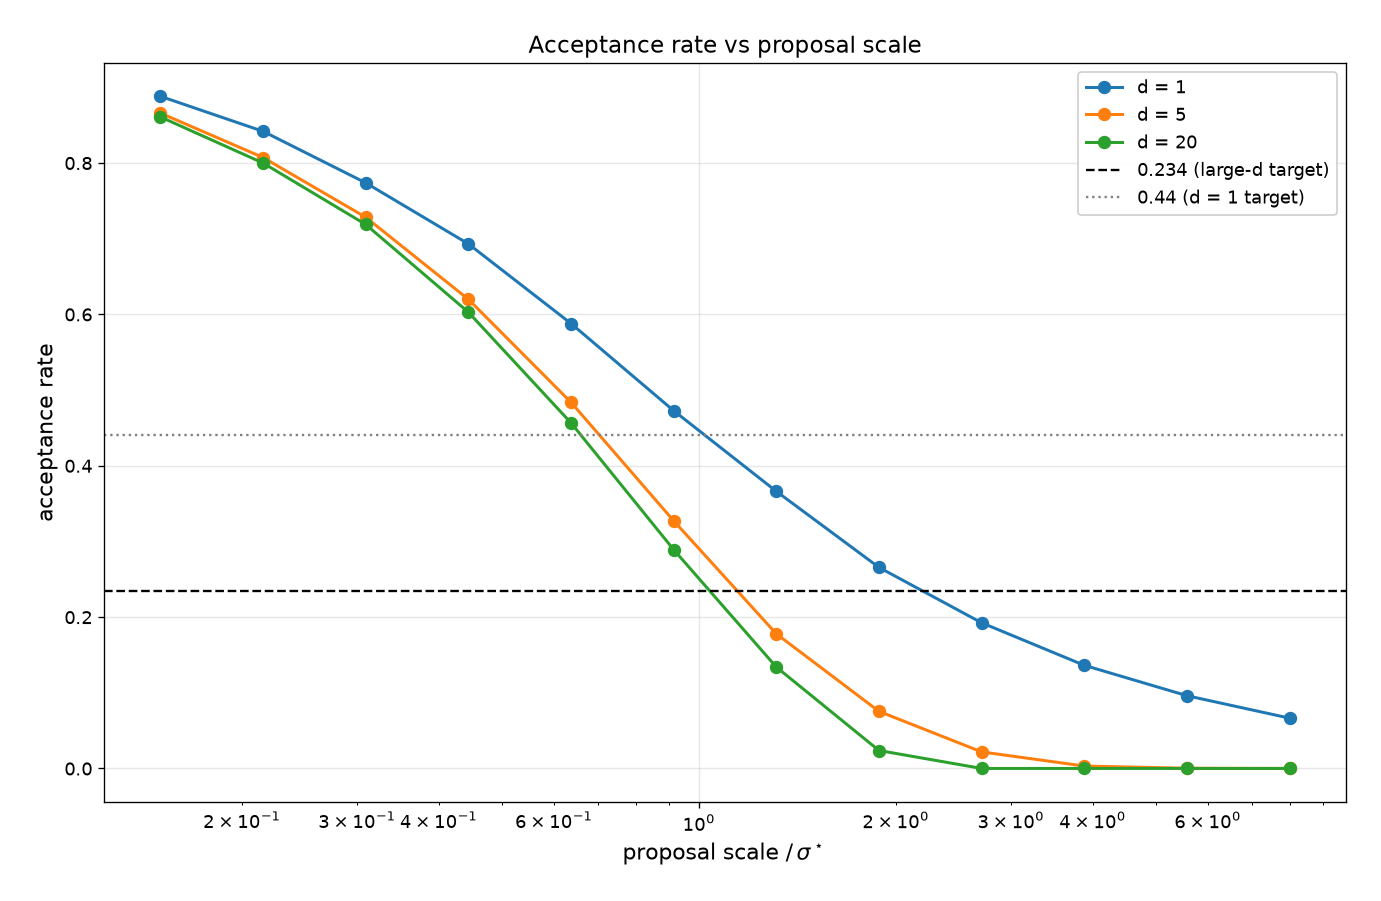
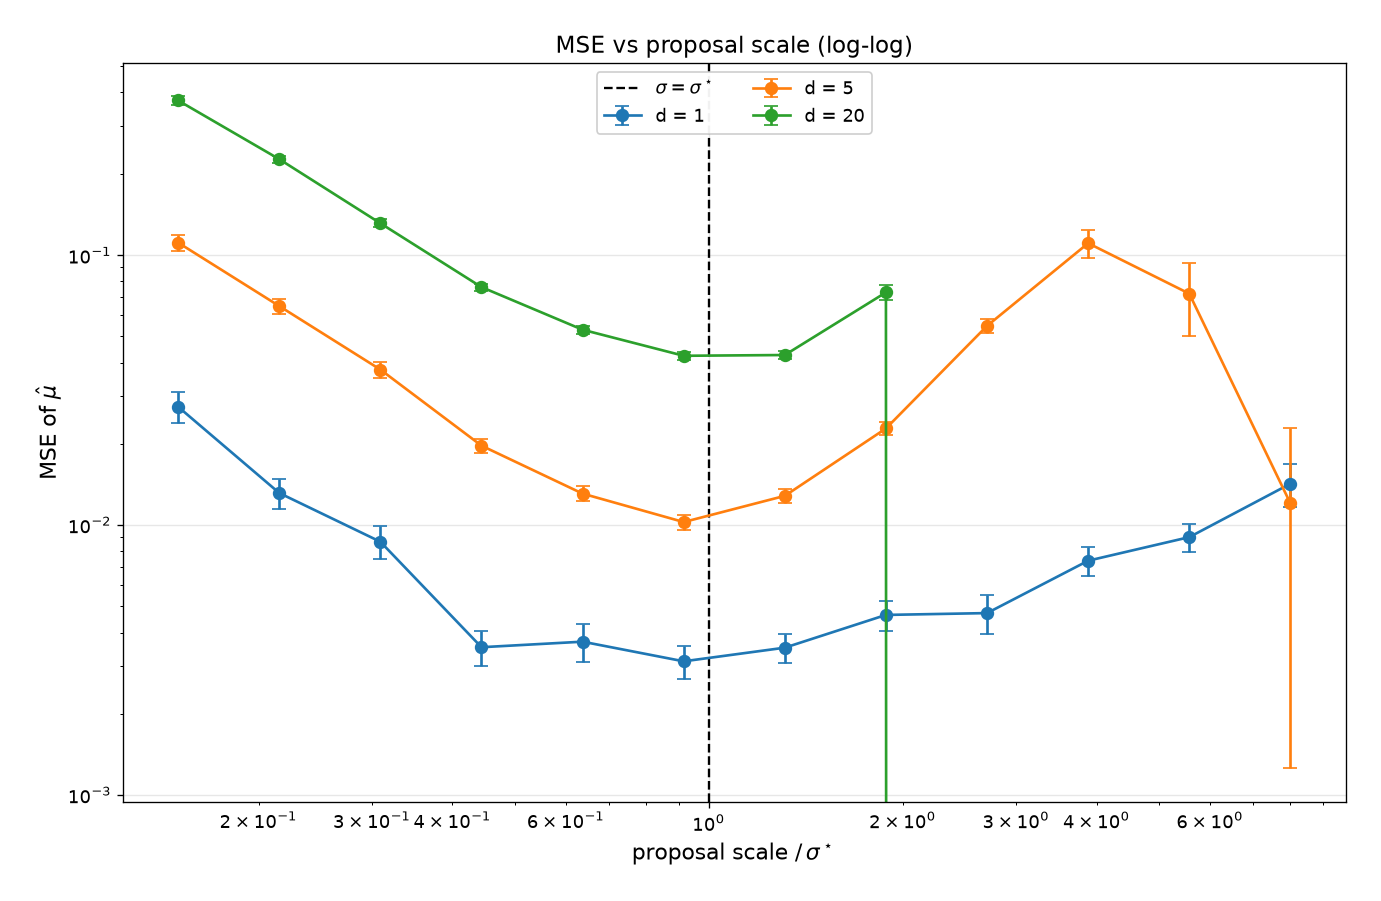
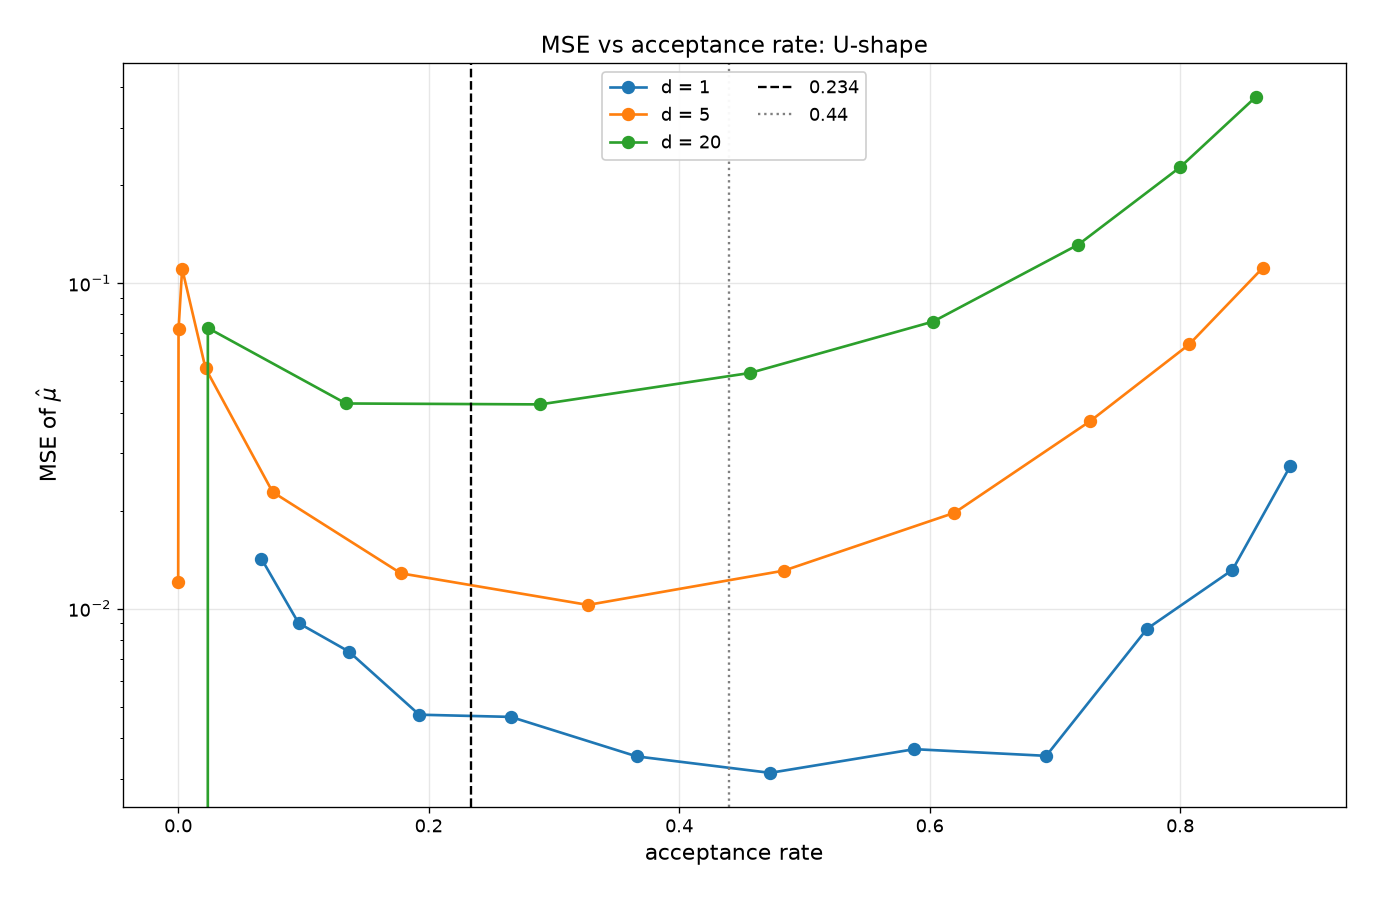
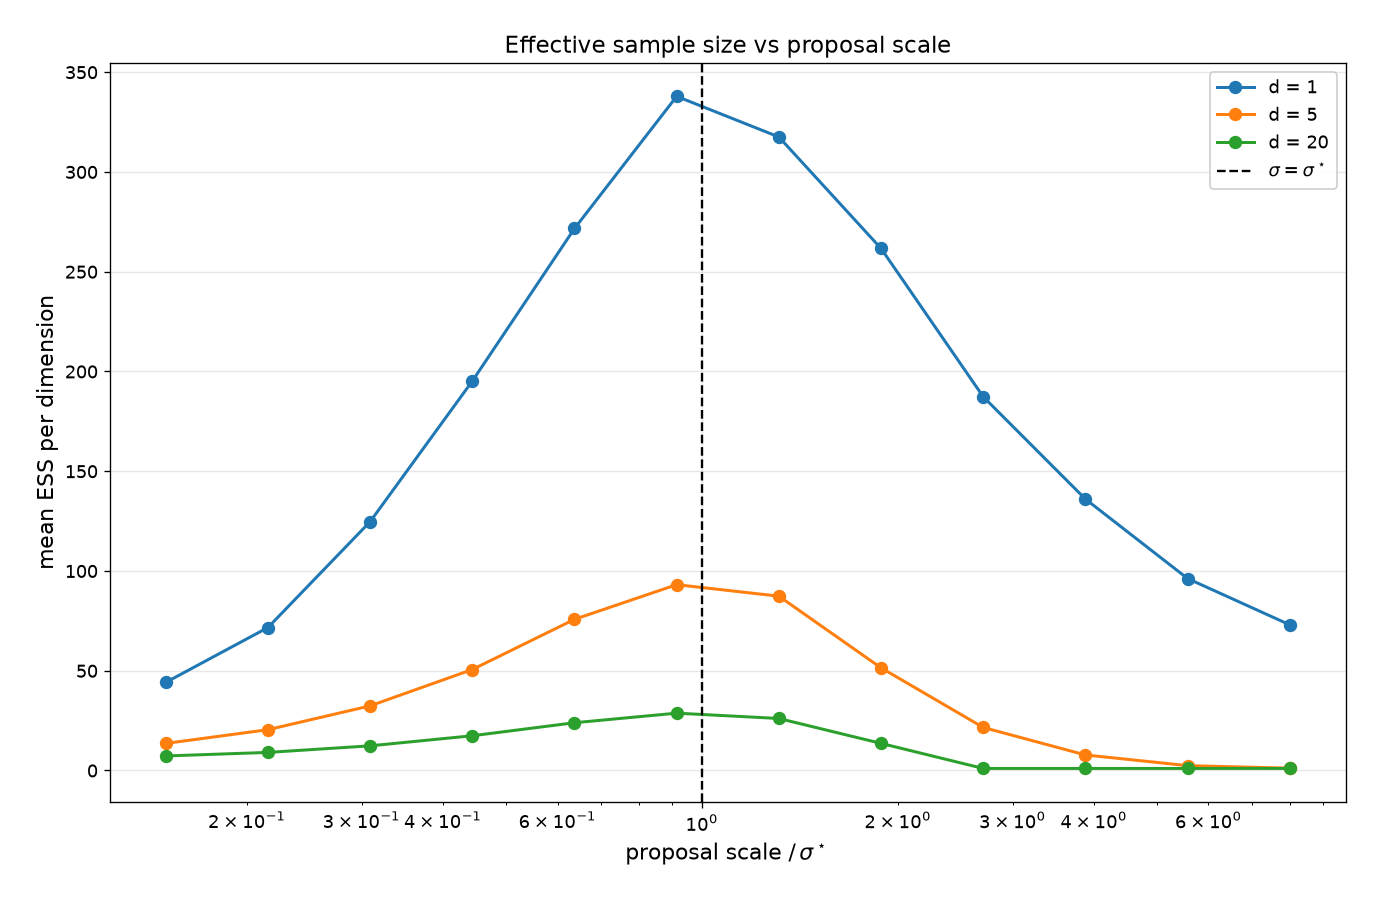
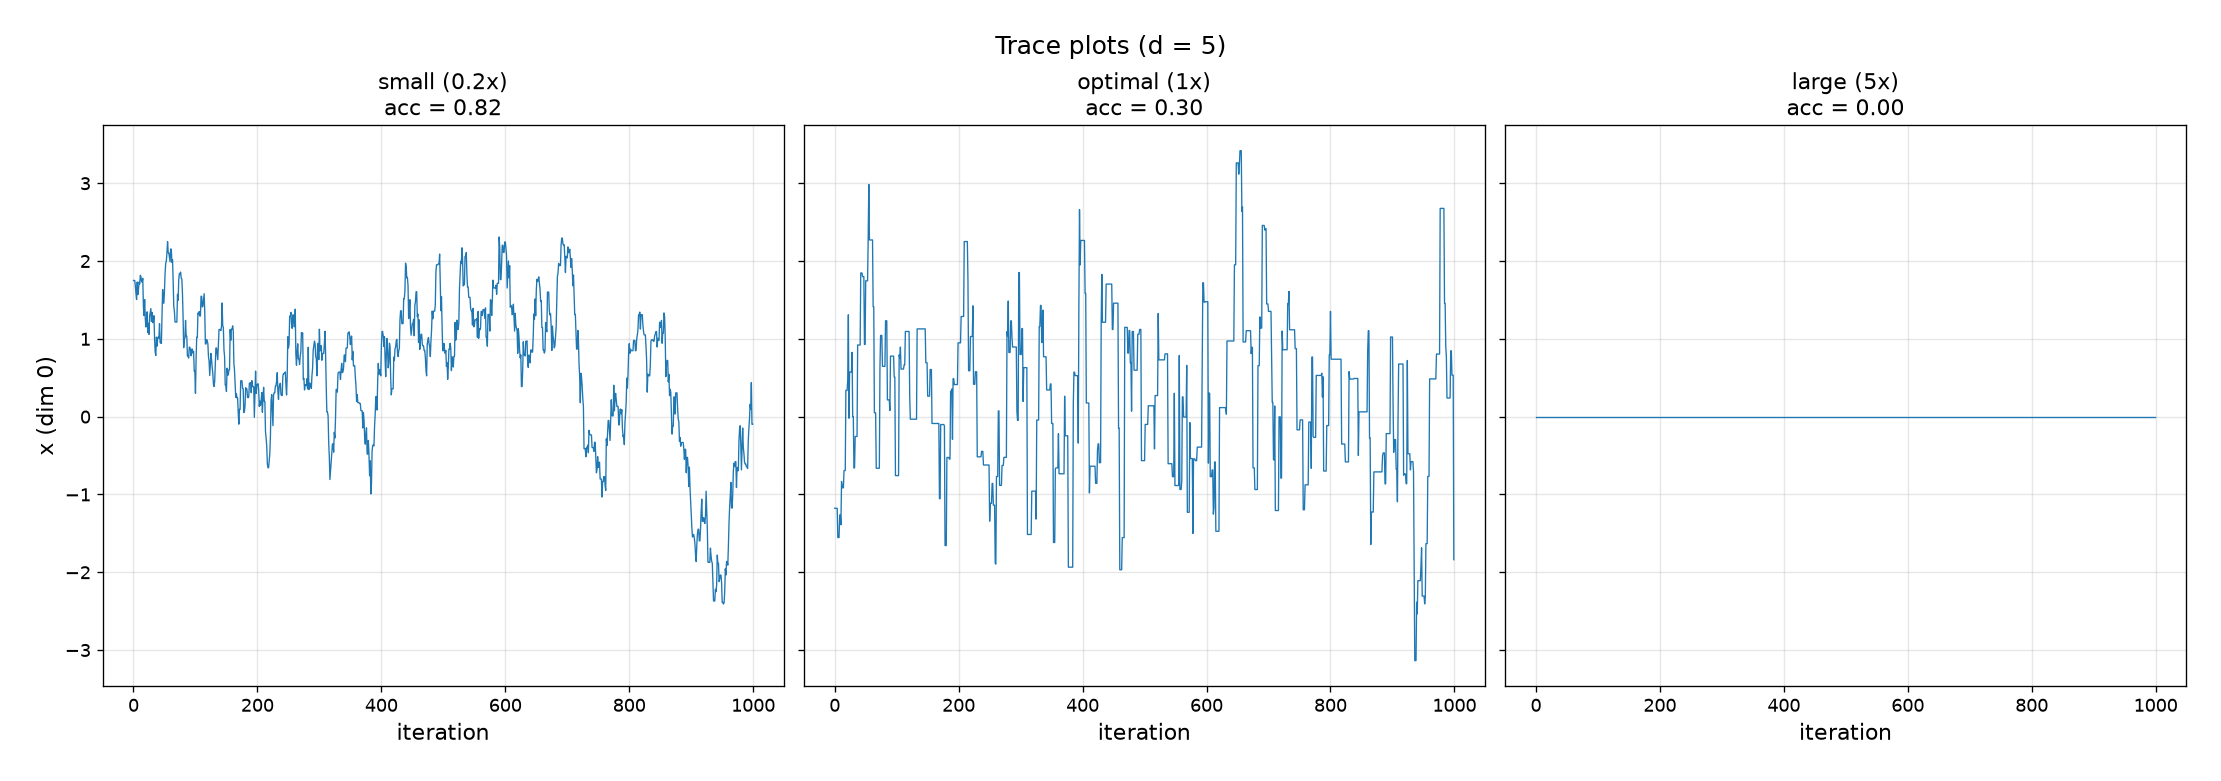
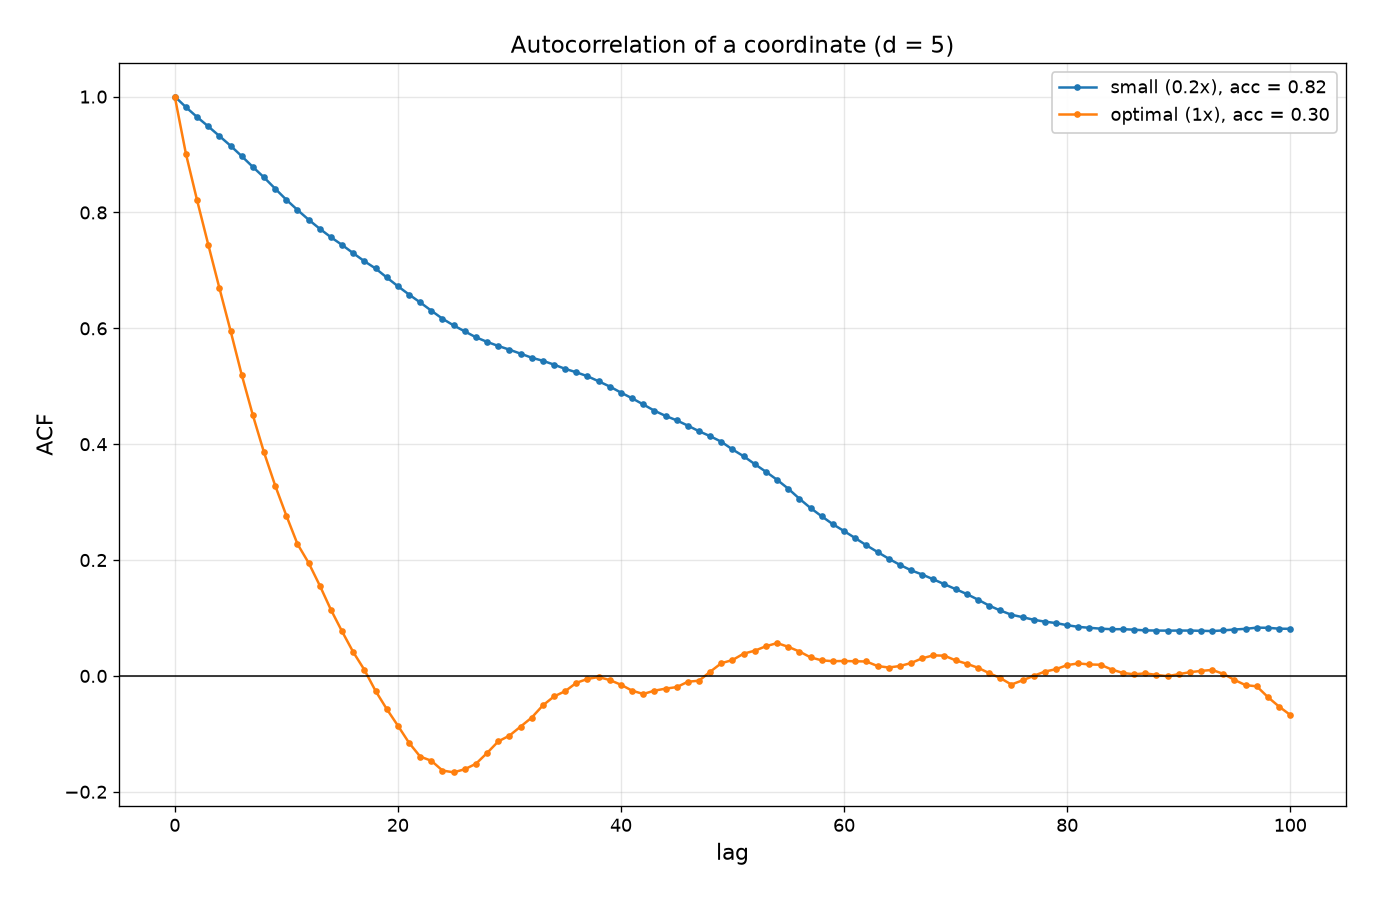
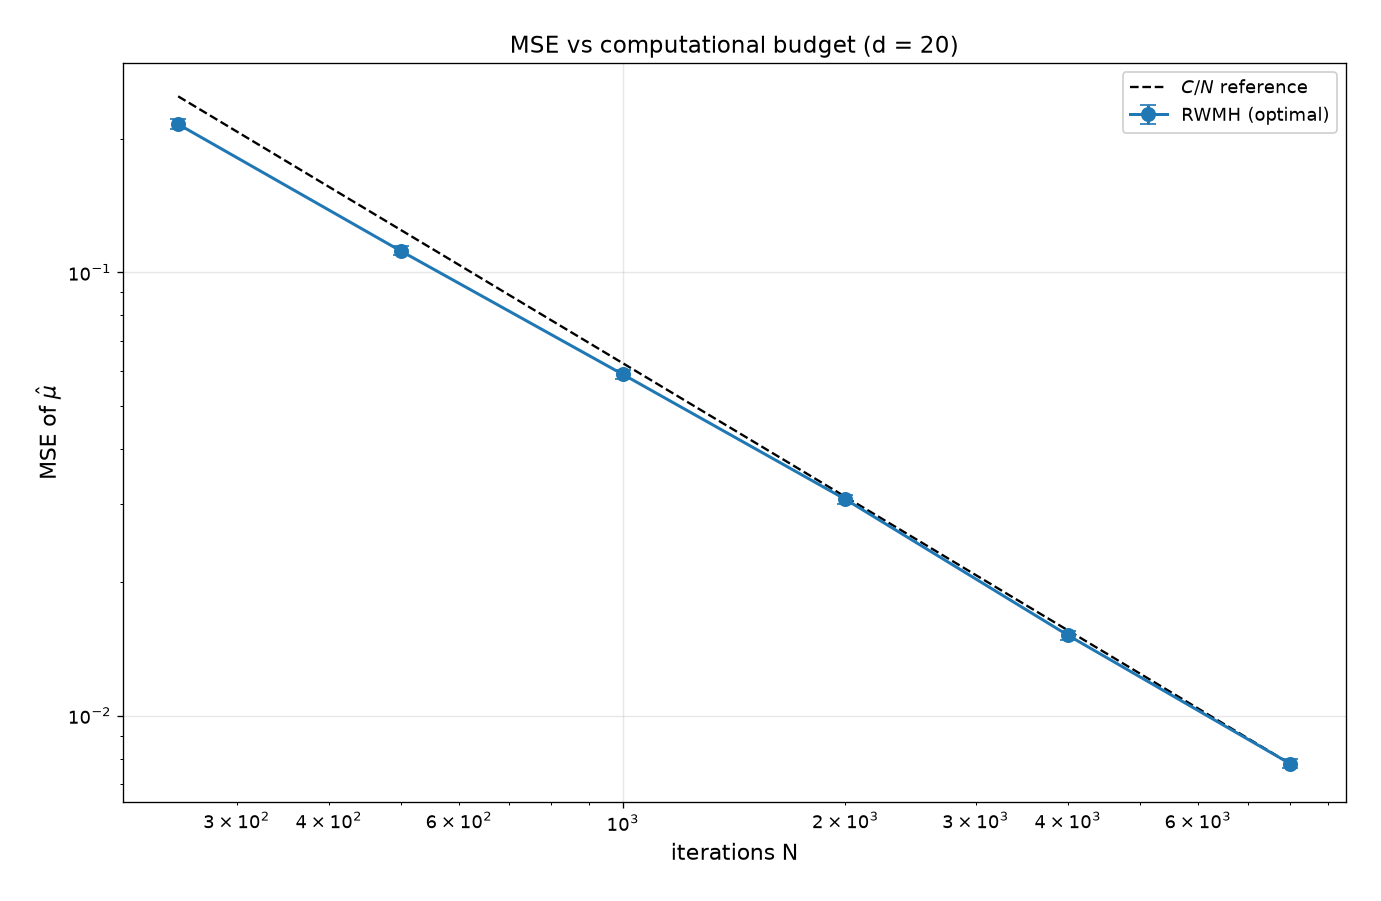
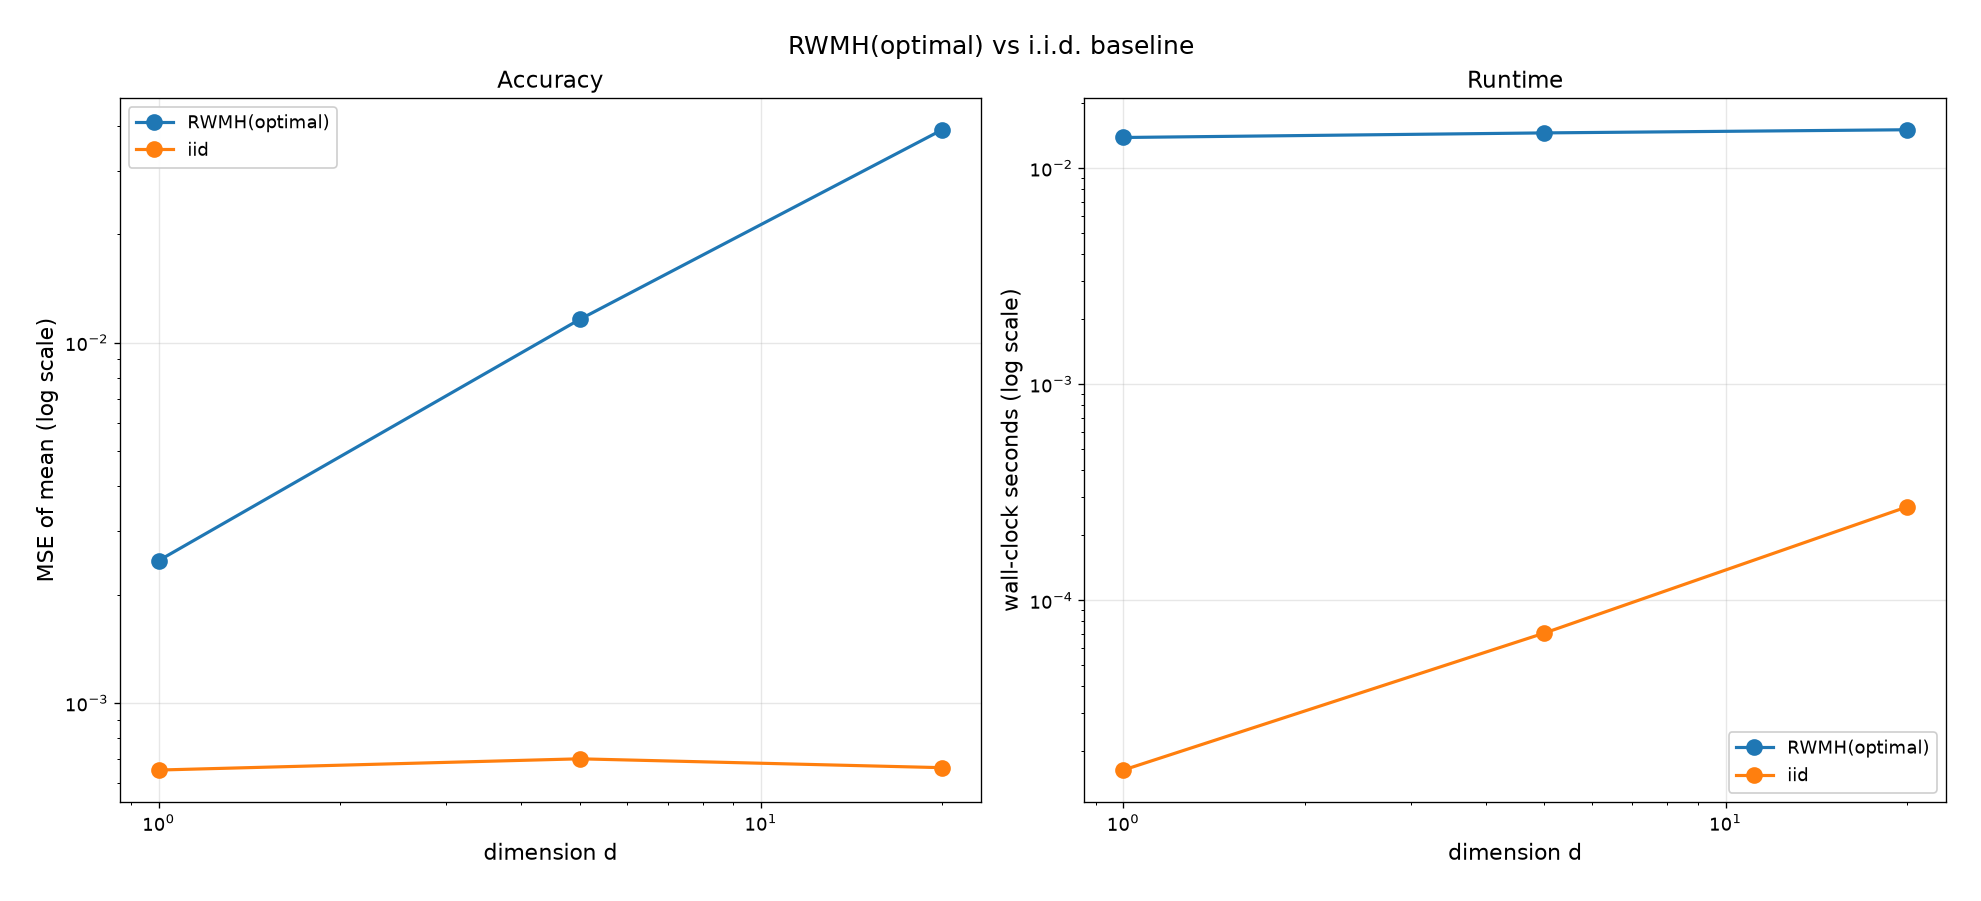
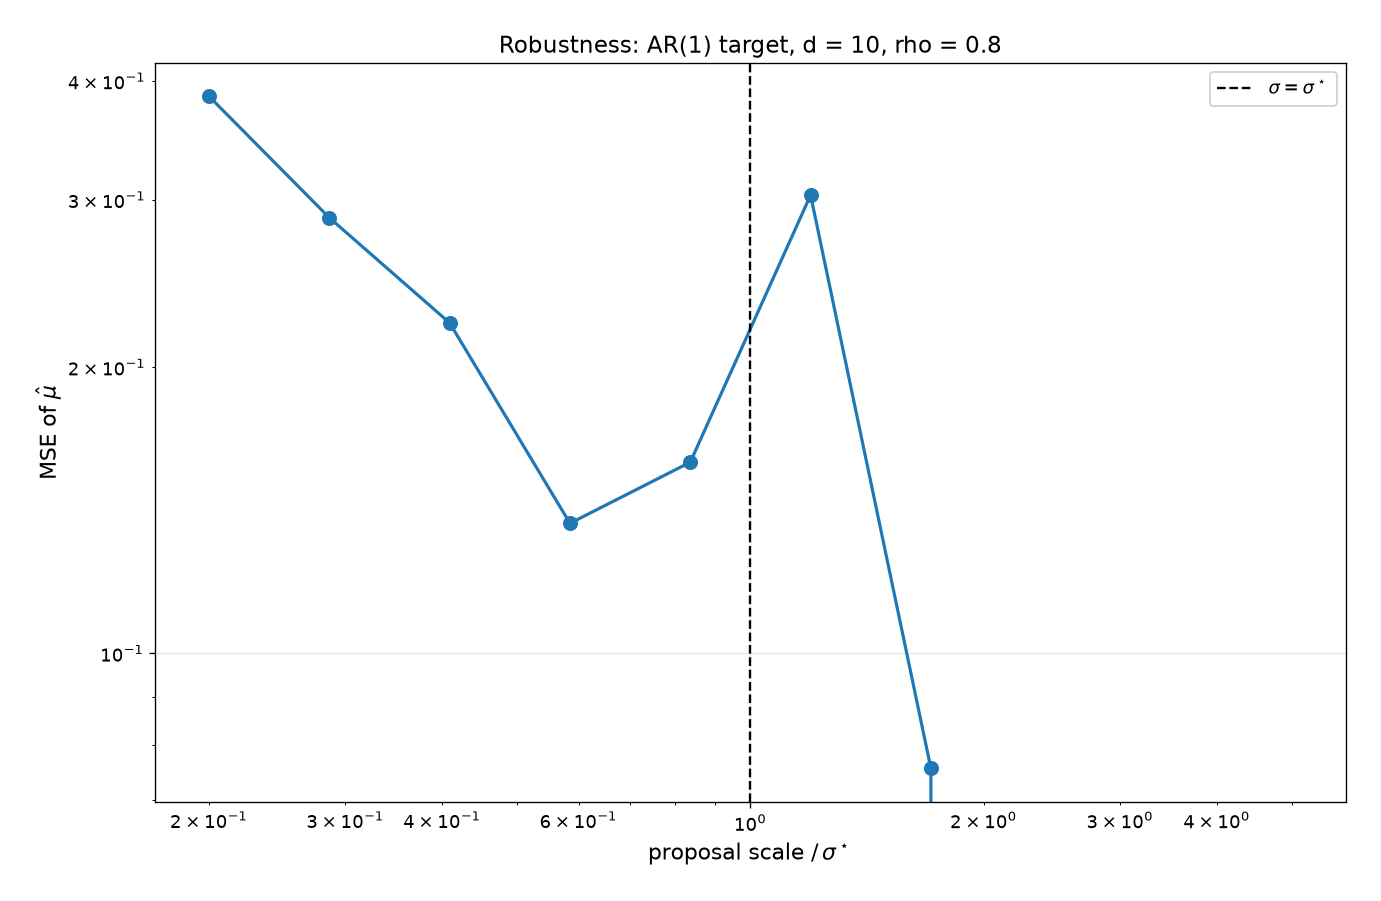